# Tiny Time Mixer (TTM) for ICU Vitals Forecasting

## Overview

This notebook implements an end-to-end pipeline for forecasting a patient's vital signs using
the **Tiny Time Mixer (TTM)** architecture. TTM is a lightweight but capable time-series
forecasting model that uses channel mixing and temporal mixing to capture patterns in
multivariate time series.

### What We'll Cover:
1. **Realistic Vitals Generation** - Simulate bedside-monitor traces for a cohort of patients
2. **Data Preparation** - Normalize, sequence, and prepare data for TTM
3. **TTM Architecture** - Implement the Tiny Time Mixer from scratch
4. **Model Training** - Train the model on multi-channel monitoring data
5. **Vitals Forecasting** - Forecast the next 2.5 hours from the last 10.5 hours
6. **Visualization** - Plot forecast against ground truth, channel by channel

### The Forecasting Problem

The monitor samples every five minutes, so:
- **Context**: 128 samples, about **10.5 hours** of history
- **Horizon**: 32 samples, about **2.5 hours** ahead

That is roughly "given the shift so far, what do the next two and a half hours look like?" -
the question a charge nurse asks at handover.

### Clinical Archetypes
Rather than random wandering, each simulated patient follows a plausible course of a stay:
- **Stable**: vitals hold near the patient's own baseline
- **Post-operative recovery**: perturbed at admission, settling back toward baseline
- **Sepsis deterioration**: a slow early drift that steepens into a sharp decline
- **Cardiac event**: a long quiet period, then an abrupt short crisis

The last two are the interesting ones. Section 7 asks specifically how well the model forecasts
**across the point where a patient starts to decline** - the clinically important failure case.

### The Channels
| Channel | Meaning | Units |
|---|---|---|
| `heart_rate` | Heart rate | beats per minute |
| `map_mmhg` | Mean arterial pressure | mmHg |
| `spo2` | Peripheral oxygen saturation | percent |
| `resp_rate` | Respiratory rate | breaths per minute |
| `acuity` | Triage acuity at admission (categorical) | 1 (least) to 4 (most) |

> **About the data.** Every patient here is simulated from published physiological reference
> ranges by `synthetic_vitals_generator.py`. No real or identifiable patient information is
> used anywhere in this course.

### About Tiny Time Mixer (TTM)
TTM is inspired by MLP-Mixer architectures and uses:
- **Temporal Mixing**: Captures patterns across time steps
- **Channel Mixing**: Captures relationships between different variables
- **Lightweight Design**: Efficient for edge deployment and real-time forecasting


---
## 1. Setup and Imports

In [1]:
# ============================================================================
# IMPORTS AND CONFIGURATION
# ============================================================================

import sys
sys.path.append('../..')   # so we can import the shared vitals generator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from typing import Tuple, List, Optional
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Sklearn for preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder

# The shared simulator: bedside-monitor trajectories for a cohort of patients
from synthetic_vitals_generator import VitalsGenerator, ARCHETYPES

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 11

# Presentation constants reused throughout the notebook
CHANNEL_LABELS = {
    'heart_rate': 'Heart rate',
    'map_mmhg': 'Mean arterial pressure',
    'spo2': 'SpO2',
    'resp_rate': 'Respiratory rate',
}
CHANNEL_UNITS = {
    'heart_rate': 'bpm',
    'map_mmhg': 'mmHg',
    'spo2': '%',
    'resp_rate': 'breaths/min',
}
CHANNEL_COLORS = {
    'heart_rate': '#e74c3c',
    'map_mmhg': '#2980b9',
    'spo2': '#16a085',
    'resp_rate': '#8e44ad',
}
ARCHETYPE_COLORS = {
    'stable': '#27ae60',
    'post_op_recovery': '#2980b9',
    'sepsis_deterioration': '#e67e22',
    'cardiac_event': '#c0392b',
}


Using device: mps


---
## 2. Generate Realistic ICU Vitals Data

We simulate continuous bedside monitoring for a cohort of patients on a high-dependency unit.
Each patient is monitored for **48 hours**, sampled every **5 minutes**, giving 576 readings
per patient.

**Clinical archetypes:**
- **Stable**: vitals hold near the patient's own baseline for the whole stay
- **Post-operative recovery**: elevated heart rate and temperature at admission, decaying back
- **Sepsis deterioration**: a slow early drift that steepens into fever, tachycardia and
  falling pressure
- **Cardiac event**: a long quiet period, then an abrupt short crisis with partial recovery

**Realistic features:**
- Per-patient baselines, so one patient rests at 62 bpm and another at 95 bpm
- Correlated (red) noise, because monitors drift rather than jitter
- A gentle circadian rhythm on heart rate, pressure and temperature
- Physiological clipping, so no trace ever leaves a possible range
- Older patients sit a little lower on pressure and saturation

Everything comes from the shared `synthetic_vitals_generator` module, which notebook 02 also
uses. These two notebooks are the documented exception to this course's self-contained rule:
both need the same multi-channel trajectories, so they share one tested generator.

In [2]:
# ============================================================================
# THE SHARED VITALS GENERATOR
# ============================================================================
#
# `VitalsGenerator` replaces the hand-rolled generator this notebook used to
# carry. It produces one tidy DataFrame for a whole cohort:
#
#     patient_id, minutes_since_admission, timestamp,
#     heart_rate, map_mmhg, spo2, resp_rate, temp_c,
#     archetype, acuity, age, sex, deteriorating
#
# `deteriorating` is the label we need in Section 7: it flips from 0 to 1 at the
# moment a sepsis or cardiac patient begins to decline.

# The four channels the model forecasts, plus the categorical one
CONTINUOUS_CHANNELS = ['heart_rate', 'map_mmhg', 'spo2', 'resp_rate']
CATEGORICAL_CHANNELS = ['acuity']

# Cohort configuration
N_PATIENTS = 45
STAY_HOURS = 48
SAMPLE_MINUTES = 5

print("Clinical archetypes available in the generator")
print("=" * 78)
print(f"{'key':<24} {'label':<26} {'prevalence':>11} {'acuity':>7}")
print("-" * 78)
for key, meta in ARCHETYPES.items():
    print(f"{key:<24} {meta['label']:<26} {meta['prevalence']:>10.0%} {meta['acuity']:>7}")
print("=" * 78)
print()
for key, meta in ARCHETYPES.items():
    print(f"{meta['label']}:")
    print(f"  {meta['description']}")

print()
print(f"Forecasting setup:")
print(f"  Sampling interval:  {SAMPLE_MINUTES} minutes")
print(f"  Readings per patient: {int(STAY_HOURS * 60 / SAMPLE_MINUTES)} ({STAY_HOURS} hours)")
print(f"  Continuous channels: {CONTINUOUS_CHANNELS}")
print(f"  Categorical channels: {CATEGORICAL_CHANNELS}")


Clinical archetypes available in the generator
key                      label                       prevalence  acuity
------------------------------------------------------------------------------
stable                   Stable                            40%       1
post_op_recovery         Post-operative recovery           25%       2
sepsis_deterioration     Sepsis deterioration              20%       3
cardiac_event            Cardiac event                     15%       4

Stable:
  Vitals hold near the patient's own baseline for the whole stay.
Post-operative recovery:
  Starts perturbed after surgery, then settles back toward baseline.
Sepsis deterioration:
  A slow early drift becomes a sharp decline: fever, tachycardia, falling pressure.
Cardiac event:
  Long quiet period, then an abrupt, short-lived crisis.

Forecasting setup:
  Sampling interval:  5 minutes
  Readings per patient: 576 (48 hours)
  Continuous channels: ['heart_rate', 'map_mmhg', 'spo2', 'resp_rate']
  Categor

In [3]:
# ============================================================================
# GENERATE THE COHORT - 45 PATIENTS, 48 HOURS OF CONTINUOUS MONITORING
# ============================================================================

generator = VitalsGenerator(seed=42, sample_minutes=SAMPLE_MINUTES)

print("Generating simulated bedside-monitor data...")
print("=" * 60)
print(f"Patients: {N_PATIENTS}")
print(f"Monitored for: {STAY_HOURS} hours each")
print(f"Sampled every: {SAMPLE_MINUTES} minutes")
print(f"Archetypes: {len(ARCHETYPES)} (stable, post-op, sepsis, cardiac)")
print("=" * 60)

# Cycle the archetypes so every clinical course is well represented
vitals_data = generator.generate_cohort(
    n_patients=N_PATIENTS,
    hours=STAY_HOURS,
    archetypes=list(ARCHETYPES),
)

print(f"\nTotal monitor readings: {len(vitals_data):,}")
print(f"Total patients: {vitals_data['patient_id'].nunique()}")
print(f"Readings per patient: {len(vitals_data) // vitals_data['patient_id'].nunique()}")

print(f"\nArchetype distribution:")
for archetype, meta in ARCHETYPES.items():
    subset = vitals_data[vitals_data['archetype'] == archetype]
    patients = subset['patient_id'].nunique()
    print(f"  {meta['label']}: {patients} patients, {len(subset):,} readings")

n_deteriorating = vitals_data.loc[vitals_data['deteriorating'] == 1, 'patient_id'].nunique()
print(f"\nPatients who deteriorate at some point: {n_deteriorating}")
print(f"Readings taken after an onset of deterioration: {int(vitals_data['deteriorating'].sum()):,}")

print(f"\nFirst 10 rows:")
vitals_data.head(10)


Generating simulated bedside-monitor data...
Patients: 45
Monitored for: 48 hours each
Sampled every: 5 minutes
Archetypes: 4 (stable, post-op, sepsis, cardiac)

Total monitor readings: 25,920
Total patients: 45
Readings per patient: 576

Archetype distribution:
  Stable: 12 patients, 6,912 readings
  Post-operative recovery: 11 patients, 6,336 readings
  Sepsis deterioration: 11 patients, 6,336 readings
  Cardiac event: 11 patients, 6,336 readings

Patients who deteriorate at some point: 22
Readings taken after an onset of deterioration: 5,450

First 10 rows:


,patient_id,minutes_since_admission,heart_rate,map_mmhg,spo2,resp_rate,temp_c,timestamp,archetype,acuity,age,sex,deteriorating
0,P0000,0,82.777812,94.305717,94.658758,12.823670,36.642287,2026-01-01 00:00:00,stable,1,68,M,0
1,P0000,5,80.964602,98.352587,94.500744,12.669219,36.647866,2026-01-01 00:05:00,stable,1,68,M,0
2,P0000,10,83.489149,94.933476,94.437392,11.995497,36.679010,2026-01-01 00:10:00,stable,1,68,M,0
3,P0000,15,85.102201,93.165049,93.829578,12.353105,36.694385,2026-01-01 00:15:00,stable,1,68,M,0
4,P0000,20,84.716849,94.052695,93.628443,12.165321,36.666943,2026-01-01 00:20:00,stable,1,68,M,0
5,P0000,25,86.793392,97.458279,93.541081,13.714291,36.689568,2026-01-01 00:25:00,stable,1,68,M,0
6,P0000,30,86.856621,94.258505,94.972907,13.960595,36.816434,2026-01-01 00:30:00,stable,1,68,M,0
7,P0000,35,84.002899,94.912713,95.710265,12.506184,36.758325,2026-01-01 00:35:00,stable,1,68,M,0
8,P0000,40,84.669810,98.543524,95.246586,13.248554,36.758737,2026-01-01 00:40:00,stable,1,68,M,0
9,P0000,45,82.249256,94.226870,94.935897,12.486604,36.810212,2026-01-01 00:45:00,stable,1,68,M,0


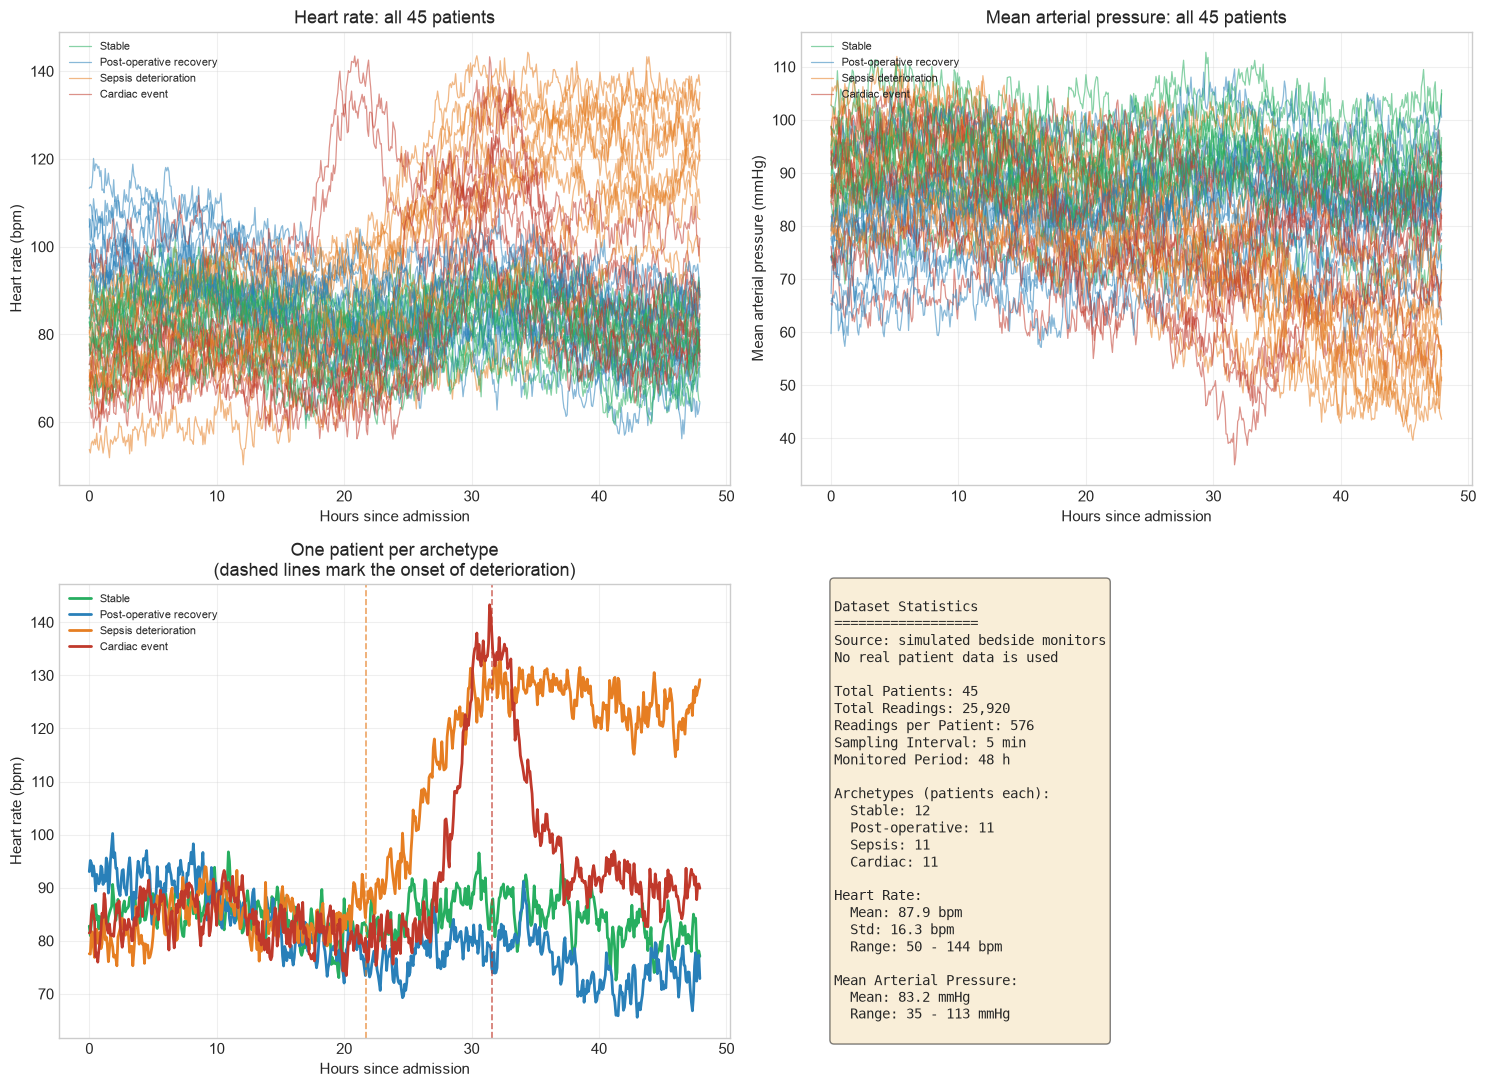

In [4]:
# ============================================================================
# VISUALIZE THE GENERATED VITALS TRAJECTORIES
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

hours_col = vitals_data['minutes_since_admission'] / 60

# Plots 1 and 2: heart rate and pressure for every patient, coloured by archetype
for ax, channel in [(axes[0, 0], 'heart_rate'), (axes[0, 1], 'map_mmhg')]:
    seen = set()
    for patient_id, g in vitals_data.groupby('patient_id', sort=False):
        archetype = g['archetype'].iloc[0]
        label = ARCHETYPES[archetype]['label'] if archetype not in seen else None
        seen.add(archetype)
        ax.plot(g['minutes_since_admission'] / 60, g[channel],
                color=ARCHETYPE_COLORS[archetype], linewidth=0.9, alpha=0.55, label=label)
    ax.set_xlabel('Hours since admission')
    ax.set_ylabel(f'{CHANNEL_LABELS[channel]} ({CHANNEL_UNITS[channel]})')
    ax.set_title(f'{CHANNEL_LABELS[channel]}: all {N_PATIENTS} patients')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

# Plot 3: one patient of each archetype, so the shapes are readable
ax3 = axes[1, 0]
for archetype, colour in ARCHETYPE_COLORS.items():
    pid = vitals_data.loc[vitals_data['archetype'] == archetype, 'patient_id'].iloc[0]
    g = vitals_data[vitals_data['patient_id'] == pid]
    ax3.plot(g['minutes_since_admission'] / 60, g['heart_rate'],
             color=colour, linewidth=2, label=ARCHETYPES[archetype]['label'])
    onset = g.loc[g['deteriorating'] == 1, 'minutes_since_admission']
    if len(onset):
        ax3.axvline(onset.min() / 60, color=colour, linestyle='--', linewidth=1.2, alpha=0.7)
ax3.set_xlabel('Hours since admission')
ax3.set_ylabel(f"Heart rate ({CHANNEL_UNITS['heart_rate']})")
ax3.set_title('One patient per archetype\n(dashed lines mark the onset of deterioration)')
ax3.legend(loc='upper left', fontsize=8)
ax3.grid(True, alpha=0.3)

# Plot 4: Dataset statistics
ax4 = axes[1, 1]
stats_text = f"""
Dataset Statistics
==================
Source: simulated bedside monitors
No real patient data is used

Total Patients: {vitals_data['patient_id'].nunique()}
Total Readings: {len(vitals_data):,}
Readings per Patient: {len(vitals_data) // vitals_data['patient_id'].nunique()}
Sampling Interval: {SAMPLE_MINUTES} min
Monitored Period: {STAY_HOURS} h

Archetypes (patients each):
  Stable: {vitals_data[vitals_data['archetype'] == 'stable']['patient_id'].nunique()}
  Post-operative: {vitals_data[vitals_data['archetype'] == 'post_op_recovery']['patient_id'].nunique()}
  Sepsis: {vitals_data[vitals_data['archetype'] == 'sepsis_deterioration']['patient_id'].nunique()}
  Cardiac: {vitals_data[vitals_data['archetype'] == 'cardiac_event']['patient_id'].nunique()}

Heart Rate:
  Mean: {vitals_data['heart_rate'].mean():.1f} bpm
  Std: {vitals_data['heart_rate'].std():.1f} bpm
  Range: {vitals_data['heart_rate'].min():.0f} - {vitals_data['heart_rate'].max():.0f} bpm

Mean Arterial Pressure:
  Mean: {vitals_data['map_mmhg'].mean():.1f} mmHg
  Range: {vitals_data['map_mmhg'].min():.0f} - {vitals_data['map_mmhg'].max():.0f} mmHg
"""
ax4.text(0.05, 0.5, stats_text, transform=ax4.transAxes, fontsize=10,
         verticalalignment='center', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax4.axis('off')

plt.tight_layout()
plt.show()


---
## 3. Data Preparation for TTM

Now we'll prepare the data for the Tiny Time Mixer model:
1. **Normalize continuous channels** - scale heart rate, pressure, SpO2 and respiratory rate to
   zero mean and unit variance, so no channel dominates the loss purely because of its units
2. **Encode acuity** - the categorical channel, scaled to [0, 1]
3. **Create sequences** - generate input/output pairs with context length 128 and horizon 32
4. **Split data** - separate into training and validation sets, never letting a sequence
   straddle two patients

In [5]:
# ============================================================================
# DATA PREPARATION
# ============================================================================

class VitalsPreprocessor:
    """
    Preprocesses bedside-monitor data for the TTM model.

    Handles:
    - Normalization of continuous channels
    - Acuity encoding
    - Sequence creation for time series forecasting
    """

    def __init__(self, continuous_cols: List[str], categorical_cols: List[str]):
        """
        Initialize preprocessor.

        Args:
            continuous_cols: List of continuous channel column names
            categorical_cols: List of categorical channel column names
        """
        self.continuous_cols = continuous_cols
        self.categorical_cols = categorical_cols
        self.scalers = {col: StandardScaler() for col in continuous_cols}
        self.label_encoders = {col: LabelEncoder() for col in categorical_cols}
        self.fitted = False

    def fit(self, df: pd.DataFrame):
        """Fit scalers and encoders on the training data."""
        for col in self.continuous_cols:
            self.scalers[col].fit(df[[col]])
        for col in self.categorical_cols:
            self.label_encoders[col].fit(df[col])
        self.fitted = True
        return self

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        """
        Transform data to normalized arrays.

        Returns:
            numpy array of shape (n_samples, n_features)
        """
        if not self.fitted:
            raise ValueError("Preprocessor not fitted. Call fit() first.")

        transformed = []
        for col in self.continuous_cols:
            transformed.append(self.scalers[col].transform(df[[col]]))
        for col in self.categorical_cols:
            # Normalize categorical to 0-1 range for consistent scaling
            encoded = self.label_encoders[col].transform(df[col])
            n_classes = len(self.label_encoders[col].classes_)
            normalized = encoded / max(n_classes - 1, 1)  # Scale to [0, 1]
            transformed.append(normalized.reshape(-1, 1))

        return np.hstack(transformed).astype(np.float32)

    def inverse_transform_continuous(self, data: np.ndarray) -> np.ndarray:
        """
        Inverse transform the continuous channels back to clinical units.

        Args:
            data: Array of shape (n_samples, n_continuous_features)

        Returns:
            Array with original scale values
        """
        result = []
        for i, col in enumerate(self.continuous_cols):
            result.append(self.scalers[col].inverse_transform(data[:, i:i+1]))
        return np.hstack(result)

    def fit_transform(self, df: pd.DataFrame) -> np.ndarray:
        """Fit and transform in one step."""
        self.fit(df)
        return self.transform(df)


In [6]:
# ============================================================================
# CREATE PYTORCH DATASET FOR TIME SERIES (INDEX-BASED FOR SHUFFLING)
# ============================================================================

class VitalsTimeSeriesDataset(Dataset):
    """
    PyTorch Dataset for vitals time series forecasting.

    Uses an index-based approach to support shuffled train/val splits,
    which prevents distribution shift between training and validation.
    """

    def __init__(
        self,
        data: np.ndarray,
        indices: List[int],
        context_length: int = 128,
        prediction_horizon: int = 32
    ):
        """
        Initialize dataset.

        Args:
            data: Full normalized data array (n_samples, n_features)
            indices: List of valid starting indices for sequences
            context_length: Number of historical time steps for input
            prediction_horizon: Number of future time steps to predict
        """
        self.data = torch.FloatTensor(data)
        self.indices = indices
        self.context_length = context_length
        self.prediction_horizon = prediction_horizon

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Get a single sequence pair.

        Returns:
            Tuple of (input_sequence, target_sequence)
            input_sequence: (context_length, n_features)
            target_sequence: (prediction_horizon, n_features)
        """
        start_idx = self.indices[idx]
        end_input = start_idx + self.context_length
        end_target = end_input + self.prediction_horizon

        x = self.data[start_idx:end_input]
        y = self.data[end_input:end_target]

        return x, y


In [7]:
# ============================================================================
# PREPARE THE DATA WITH SHUFFLED TRAIN/VAL SPLIT
# ============================================================================

from sklearn.model_selection import train_test_split

# Configuration
CONTEXT_LENGTH = 128       # 128 samples at 5 minutes = 10 h 40 min of history
PREDICTION_HORIZON = 32    # 32 samples at 5 minutes = 2 h 40 min ahead
BATCH_SIZE = 32

# Define columns - exclude patient_id, archetype and the label from model input
continuous_cols = CONTINUOUS_CHANNELS
categorical_cols = CATEGORICAL_CHANNELS

# Normalize the ENTIRE dataset (fit on all data since we'll shuffle)
preprocessor = VitalsPreprocessor(continuous_cols, categorical_cols)
all_normalized = preprocessor.fit_transform(vitals_data)

print(f"Total data points: {len(all_normalized):,}")
print(f"Normalized data shape: {all_normalized.shape}")
print(f"Features: {continuous_cols + categorical_cols}")
print(f"\nContext: {CONTEXT_LENGTH} samples = {CONTEXT_LENGTH * SAMPLE_MINUTES / 60:.1f} hours")
print(f"Horizon: {PREDICTION_HORIZON} samples = {PREDICTION_HORIZON * SAMPLE_MINUTES / 60:.1f} hours")

# Create sequence indices, but respect patient boundaries
# (never create a sequence that spans two patients)
all_indices = []
for patient_id in vitals_data['patient_id'].unique():
    patient_mask = vitals_data['patient_id'] == patient_id
    patient_start = patient_mask.idxmax()          # First row index for this patient
    patient_end = patient_mask[::-1].idxmax()      # Last row index for this patient
    patient_length = patient_end - patient_start + 1

    # Calculate valid sequence start indices within this patient's record
    n_sequences = patient_length - CONTEXT_LENGTH - PREDICTION_HORIZON + 1
    if n_sequences > 0:
        patient_indices = list(range(patient_start, patient_start + n_sequences))
        all_indices.extend(patient_indices)

print(f"\nTotal valid sequences (respecting patient boundaries): {len(all_indices):,}")

# Shuffle and split indices (80/20 split)
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print(f"Training sequences: {len(train_indices):,}")
print(f"Validation sequences: {len(val_indices):,}")


Total data points: 25,920
Normalized data shape: (25920, 5)
Features: ['heart_rate', 'map_mmhg', 'spo2', 'resp_rate', 'acuity']

Context: 128 samples = 10.7 hours
Horizon: 32 samples = 2.7 hours

Total valid sequences (respecting patient boundaries): 18,765
Training sequences: 15,012
Validation sequences: 3,753


In [8]:
# ============================================================================
# CREATE PYTORCH DATASETS AND DATALOADERS
# ============================================================================

# Create datasets using shuffled indices
train_dataset = VitalsTimeSeriesDataset(
    all_normalized,
    indices=train_indices,
    context_length=CONTEXT_LENGTH,
    prediction_horizon=PREDICTION_HORIZON
)

val_dataset = VitalsTimeSeriesDataset(
    all_normalized,
    indices=val_indices,
    context_length=CONTEXT_LENGTH,
    prediction_horizon=PREDICTION_HORIZON
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Training sequences: {len(train_dataset)}")
print(f"Validation sequences: {len(val_dataset)}")
print(f"\nTraining batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# Verify a sample batch
sample_x, sample_y = next(iter(train_loader))
print(f"\nSample input shape: {sample_x.shape}")
print(f"Sample target shape: {sample_y.shape}")


Training sequences: 15012
Validation sequences: 3753

Training batches per epoch: 469
Validation batches: 118

Sample input shape: torch.Size([32, 128, 5])
Sample target shape: torch.Size([32, 32, 5])


---
## 4. Tiny Time Mixer (TTM) Model Architecture

The Tiny Time Mixer architecture consists of:

1. **Patch Embedding**: Divide the input sequence into patches and embed them
2. **Mixer Blocks**: Alternating between:
   - **Temporal Mixing**: MLPs that mix information across time steps
   - **Channel Mixing**: MLPs that mix information across features
3. **Prediction Head**: Map the mixed representations to future predictions

### Key Design Choices:
- **All MLP architecture**: No attention mechanisms, making it efficient
- **Patch-based**: Reduces sequence length and captures local patterns
- **Separate mixing**: Disentangles temporal and channel dependencies

In [9]:
# ============================================================================
# TINY TIME MIXER MODEL COMPONENTS
# ============================================================================

class MixerMLP(nn.Module):
    """
    MLP block used for both temporal and channel mixing.
    
    Architecture: Linear -> GELU -> Dropout -> Linear -> Dropout
    """
    
    def __init__(
        self, 
        input_dim: int, 
        hidden_dim: int, 
        output_dim: int, 
        dropout: float = 0.1
    ):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.activation = nn.GELU()
        self.dropout1 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, output_dim)
        self.dropout2 = nn.Dropout(dropout)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.fc1(x)
        x = self.activation(x)
        x = self.dropout1(x)
        x = self.fc2(x)
        x = self.dropout2(x)
        return x


class MixerBlock(nn.Module):
    """
    A single mixer block with temporal mixing followed by channel mixing.
    
    Both mixing operations use residual connections and layer normalization.
    """
    
    def __init__(
        self, 
        n_patches: int, 
        n_channels: int, 
        temporal_hidden_dim: int,
        channel_hidden_dim: int,
        dropout: float = 0.1
    ):
        super().__init__()
        
        # Temporal mixing: mix across patches (time dimension)
        self.temporal_norm = nn.LayerNorm(n_channels)
        self.temporal_mlp = MixerMLP(
            n_patches, temporal_hidden_dim, n_patches, dropout
        )
        
        # Channel mixing: mix across features
        self.channel_norm = nn.LayerNorm(n_channels)
        self.channel_mlp = MixerMLP(
            n_channels, channel_hidden_dim, n_channels, dropout
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Input tensor of shape (batch, n_patches, n_channels)
            
        Returns:
            Output tensor of shape (batch, n_patches, n_channels)
        """
        # Temporal mixing: transpose to mix across patches
        # (batch, patches, channels) -> (batch, channels, patches)
        residual = x
        x = self.temporal_norm(x)
        x = x.transpose(1, 2)  # (batch, channels, patches)
        x = self.temporal_mlp(x)
        x = x.transpose(1, 2)  # (batch, patches, channels)
        x = x + residual
        
        # Channel mixing
        residual = x
        x = self.channel_norm(x)
        x = self.channel_mlp(x)
        x = x + residual
        
        return x


class PatchEmbedding(nn.Module):
    """
    Embeds input time series into patches.
    
    Divides the input sequence into non-overlapping patches and
    projects them to the embedding dimension.
    """
    
    def __init__(
        self, 
        patch_size: int, 
        n_features: int, 
        embed_dim: int
    ):
        super().__init__()
        self.patch_size = patch_size
        self.n_features = n_features
        self.embed_dim = embed_dim
        
        # Linear projection from patch to embedding
        self.projection = nn.Linear(patch_size * n_features, embed_dim)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Input tensor of shape (batch, seq_len, n_features)
            
        Returns:
            Patch embeddings of shape (batch, n_patches, embed_dim)
        """
        batch_size, seq_len, n_features = x.shape
        n_patches = seq_len // self.patch_size
        
        # Reshape to patches: (batch, n_patches, patch_size * n_features)
        x = x[:, :n_patches * self.patch_size, :]  # Trim to fit patches
        x = x.reshape(batch_size, n_patches, self.patch_size * n_features)
        
        # Project to embedding dimension
        x = self.projection(x)
        
        return x

In [10]:
# ============================================================================
# COMPLETE TINY TIME MIXER MODEL
# ============================================================================

class TinyTimeMixer(nn.Module):
    """
    Tiny Time Mixer (TTM) for multivariate time series forecasting.
    
    Architecture:
    1. Patch embedding layer
    2. Stack of mixer blocks (temporal + channel mixing)
    3. Prediction head to generate future values
    
    This implementation forecasts patient vital signs: future heart rate,
    mean arterial pressure, SpO2 and respiratory rate.
    """
    
    def __init__(
        self,
        context_length: int = 128,
        prediction_horizon: int = 32,
        n_features: int = 5,
        patch_size: int = 8,
        embed_dim: int = 64,
        n_mixer_blocks: int = 4,
        temporal_hidden_ratio: float = 2.0,
        channel_hidden_ratio: float = 2.0,
        dropout: float = 0.1
    ):
        """
        Initialize TTM model.
        
        Args:
            context_length: Number of input time steps
            prediction_horizon: Number of future time steps to predict
            n_features: Number of input features
            patch_size: Size of each patch
            embed_dim: Embedding dimension for patches
            n_mixer_blocks: Number of mixer blocks
            temporal_hidden_ratio: Hidden dim ratio for temporal MLP
            channel_hidden_ratio: Hidden dim ratio for channel MLP
            dropout: Dropout probability
        """
        super().__init__()
        
        self.context_length = context_length
        self.prediction_horizon = prediction_horizon
        self.n_features = n_features
        self.patch_size = patch_size
        self.n_patches = context_length // patch_size
        
        # Patch embedding
        self.patch_embedding = PatchEmbedding(
            patch_size=patch_size,
            n_features=n_features,
            embed_dim=embed_dim
        )
        
        # Positional embedding for patches
        self.positional_embedding = nn.Parameter(
            torch.randn(1, self.n_patches, embed_dim) * 0.02
        )
        
        # Mixer blocks
        temporal_hidden_dim = int(self.n_patches * temporal_hidden_ratio)
        channel_hidden_dim = int(embed_dim * channel_hidden_ratio)
        
        self.mixer_blocks = nn.ModuleList([
            MixerBlock(
                n_patches=self.n_patches,
                n_channels=embed_dim,
                temporal_hidden_dim=temporal_hidden_dim,
                channel_hidden_dim=channel_hidden_dim,
                dropout=dropout
            )
            for _ in range(n_mixer_blocks)
        ])
        
        # Final layer norm
        self.final_norm = nn.LayerNorm(embed_dim)
        
        # Prediction head: flatten and project to output
        self.prediction_head = nn.Sequential(
            nn.Linear(self.n_patches * embed_dim, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, prediction_horizon * n_features)
        )
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        """Initialize weights using Xavier/Glorot initialization."""
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of TTM.
        
        Args:
            x: Input tensor of shape (batch, context_length, n_features)
            
        Returns:
            Predictions of shape (batch, prediction_horizon, n_features)
        """
        batch_size = x.shape[0]
        
        # Embed patches
        x = self.patch_embedding(x)  # (batch, n_patches, embed_dim)
        
        # Add positional embedding
        x = x + self.positional_embedding
        
        # Apply mixer blocks
        for mixer_block in self.mixer_blocks:
            x = mixer_block(x)
        
        # Final normalization
        x = self.final_norm(x)
        
        # Flatten and predict
        x = x.reshape(batch_size, -1)  # (batch, n_patches * embed_dim)
        x = self.prediction_head(x)    # (batch, prediction_horizon * n_features)
        
        # Reshape to (batch, prediction_horizon, n_features)
        x = x.reshape(batch_size, self.prediction_horizon, self.n_features)
        
        return x
    
    def get_num_parameters(self) -> int:
        """Return total number of trainable parameters."""
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

In [11]:
# ============================================================================
# INSTANTIATE THE MODEL (REDUCED SIZE TO PREVENT OVERFITTING)
# ============================================================================

# Model configuration - REDUCED to prevent overfitting
# Original: 378K params -> New: ~60K params
N_FEATURES = all_normalized.shape[1]  # heart_rate, map_mmhg, spo2, resp_rate, acuity
PATCH_SIZE = 16          # Was 8 -> fewer patches = simpler model
EMBED_DIM = 32           # Was 64 -> smaller embedding
N_MIXER_BLOCKS = 2       # Was 4 -> shallower network
DROPOUT = 0.3            # Was 0.1 -> more regularization

# Create model
model = TinyTimeMixer(
    context_length=CONTEXT_LENGTH,
    prediction_horizon=PREDICTION_HORIZON,
    n_features=N_FEATURES,
    patch_size=PATCH_SIZE,
    embed_dim=EMBED_DIM,
    n_mixer_blocks=N_MIXER_BLOCKS,
    dropout=DROPOUT
).to(device)

print("Model Architecture (REDUCED for better generalization):")
print("=" * 50)
print(model)
print("=" * 50)
print(f"\nTotal trainable parameters: {model.get_num_parameters():,}")
print(f"\nModel Configuration:")
print(f"  Context Length: {CONTEXT_LENGTH}")
print(f"  Prediction Horizon: {PREDICTION_HORIZON}")
print(f"  Number of Features: {N_FEATURES}")
print(f"  Patch Size: {PATCH_SIZE}")
print(f"  Number of Patches: {CONTEXT_LENGTH // PATCH_SIZE}")
print(f"  Embedding Dimension: {EMBED_DIM}")
print(f"  Number of Mixer Blocks: {N_MIXER_BLOCKS}")
print(f"  Dropout: {DROPOUT}")

Model Architecture (REDUCED for better generalization):
TinyTimeMixer(
  (patch_embedding): PatchEmbedding(
    (projection): Linear(in_features=80, out_features=32, bias=True)
  )
  (mixer_blocks): ModuleList(
    (0-1): 2 x MixerBlock(
      (temporal_norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (temporal_mlp): MixerMLP(
        (fc1): Linear(in_features=8, out_features=16, bias=True)
        (activation): GELU(approximate='none')
        (dropout1): Dropout(p=0.3, inplace=False)
        (fc2): Linear(in_features=16, out_features=8, bias=True)
        (dropout2): Dropout(p=0.3, inplace=False)
      )
      (channel_norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (channel_mlp): MixerMLP(
        (fc1): Linear(in_features=32, out_features=64, bias=True)
        (activation): GELU(approximate='none')
        (dropout1): Dropout(p=0.3, inplace=False)
        (fc2): Linear(in_features=64, out_features=32, bias=True)
        (dro

In [12]:
# ============================================================================
# VERIFY MODEL WITH A FORWARD PASS
# ============================================================================

# Test forward pass
test_input = sample_x.to(device)
test_output = model(test_input)

print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")
print(f"\nExpected output shape: ({BATCH_SIZE}, {PREDICTION_HORIZON}, {N_FEATURES})")
print(f"Match: {test_output.shape == (BATCH_SIZE, PREDICTION_HORIZON, N_FEATURES)}")

Input shape: torch.Size([32, 128, 5])
Output shape: torch.Size([32, 32, 5])

Expected output shape: (32, 32, 5)
Match: True


---
## 5. Training Loop

Now we'll implement the complete training pipeline including:
- Loss function (MSE)
- Optimizer (AdamW)
- Learning rate scheduler
- Training and validation loops
- Early stopping

In [13]:
# ============================================================================
# TRAINING UTILITIES
# ============================================================================

class EarlyStopping:
    """
    Early stopping to halt training when validation loss stops improving.
    """
    
    def __init__(self, patience: int = 10, min_delta: float = 1e-6):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.should_stop = False
        self.best_model_state = None
    
    def __call__(self, val_loss: float, model: nn.Module) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_model_state = model.state_dict().copy()
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop
    
    def restore_best_model(self, model: nn.Module):
        """Restore the best model state."""
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_epoch(
    model: nn.Module, 
    dataloader: DataLoader, 
    criterion: nn.Module, 
    optimizer: optim.Optimizer,
    device: torch.device
) -> float:
    """
    Train for one epoch.
    
    Returns:
        Average training loss for the epoch
    """
    model.train()
    total_loss = 0.0
    
    for batch_x, batch_y in dataloader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        
        # Forward pass
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        
        # Backward pass
        loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(dataloader)


def validate(
    model: nn.Module, 
    dataloader: DataLoader, 
    criterion: nn.Module,
    device: torch.device
) -> Tuple[float, float]:
    """
    Validate the model.
    
    Returns:
        Tuple of (MSE loss, MAE loss)
    """
    model.eval()
    total_mse = 0.0
    total_mae = 0.0
    
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            
            predictions = model(batch_x)
            
            mse = criterion(predictions, batch_y)
            mae = torch.mean(torch.abs(predictions - batch_y))
            
            total_mse += mse.item()
            total_mae += mae.item()
    
    return total_mse / len(dataloader), total_mae / len(dataloader)

In [14]:
# ============================================================================
# TRAINING CONFIGURATION (ADJUSTED FOR BETTER GENERALIZATION)
# ============================================================================

# Hyperparameters - adjusted for smaller model and more data
LEARNING_RATE = 3e-4     # Was 1e-3 -> slower learning for stability
WEIGHT_DECAY = 1e-2      # Was 1e-4 -> stronger L2 regularization
N_EPOCHS = 150           # Was 100 -> more epochs with slower LR
PATIENCE = 20            # Was 15 -> more patience

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.AdamW(
    model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler (cosine annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, 
    T_max=N_EPOCHS, 
    eta_min=1e-6
)

# Early stopping
early_stopping = EarlyStopping(patience=PATIENCE)

print("Training Configuration (ADJUSTED):")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Weight Decay: {WEIGHT_DECAY}")
print(f"  Max Epochs: {N_EPOCHS}")
print(f"  Early Stopping Patience: {PATIENCE}")
print(f"  Loss Function: MSE")
print(f"  Optimizer: AdamW")
print(f"  LR Scheduler: CosineAnnealing")

Training Configuration (ADJUSTED):
  Learning Rate: 0.0003
  Weight Decay: 0.01
  Max Epochs: 150
  Early Stopping Patience: 20
  Loss Function: MSE
  Optimizer: AdamW
  LR Scheduler: CosineAnnealing


In [15]:
# ============================================================================
# TRAINING LOOP
# ============================================================================

# Storage for training history
history = {
    'train_loss': [],
    'val_loss': [],
    'val_mae': [],
    'lr': []
}

print("Starting Training...")
print("=" * 70)

for epoch in range(N_EPOCHS):
    # Training
    train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validation
    val_loss, val_mae = validate(model, val_loader, criterion, device)
    
    # Get current learning rate
    current_lr = optimizer.param_groups[0]['lr']
    
    # Store history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_mae'].append(val_mae)
    history['lr'].append(current_lr)
    
    # Print progress
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:3d}/{N_EPOCHS} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f} | "
            f"Val MAE: {val_mae:.6f} | "
            f"LR: {current_lr:.2e}"
        )
    
    # Step scheduler
    scheduler.step()
    
    # Early stopping check
    if early_stopping(val_loss, model):
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        print(f"Best validation loss: {early_stopping.best_loss:.6f}")
        break

# Restore best model
early_stopping.restore_best_model(model)
print("\nTraining complete! Best model restored.")
print("=" * 70)

Starting Training...


Epoch   1/150 | Train Loss: 0.433633 | Val Loss: 0.122552 | Val MAE: 0.261736 | LR: 3.00e-04


Epoch   5/150 | Train Loss: 0.100618 | Val Loss: 0.075667 | Val MAE: 0.201017 | LR: 2.99e-04


Epoch  10/150 | Train Loss: 0.081532 | Val Loss: 0.067128 | Val MAE: 0.187424 | LR: 2.97e-04


Epoch  15/150 | Train Loss: 0.076324 | Val Loss: 0.064322 | Val MAE: 0.183496 | LR: 2.94e-04


...

Epoch 130/150 | Train Loss: 0.060332 | Val Loss: 0.049615 | Val MAE: 0.160826 | LR: 1.52e-05


Epoch 135/150 | Train Loss: 0.060074 | Val Loss: 0.049627 | Val MAE: 0.160821 | LR: 9.32e-06


Epoch 140/150 | Train Loss: 0.059899 | Val Loss: 0.049623 | Val MAE: 0.160919 | LR: 4.95e-06


Epoch 145/150 | Train Loss: 0.059795 | Val Loss: 0.049592 | Val MAE: 0.160772 | LR: 2.18e-06


Epoch 150/150 | Train Loss: 0.060178 | Val Loss: 0.049573 | Val MAE: 0.160817 | LR: 1.03e-06

Training complete! Best model restored.


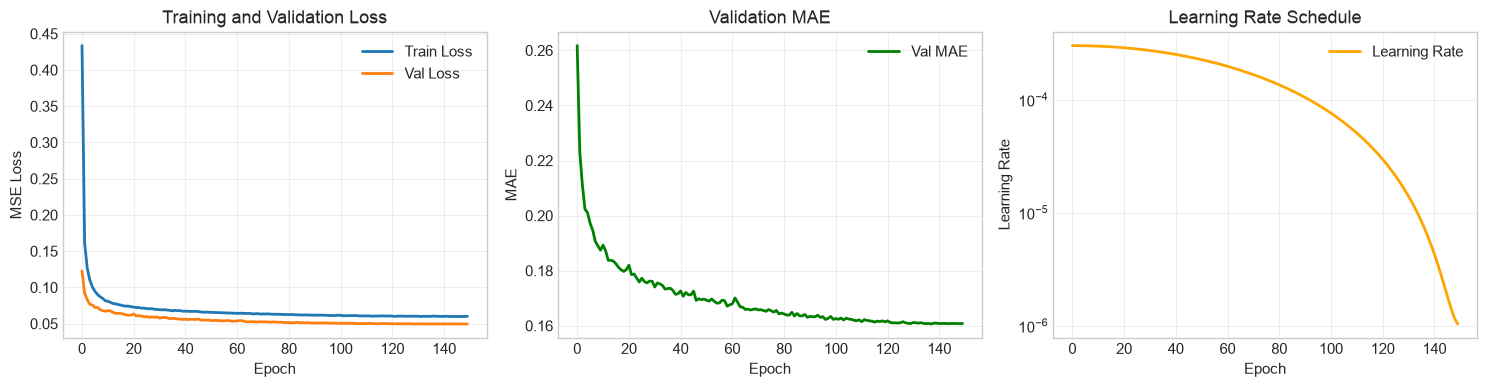


Final Metrics:
  Best Validation Loss (MSE): 0.049545
  Final Validation MAE: 0.160817


In [16]:
# ============================================================================
# VISUALIZE TRAINING HISTORY
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: Training and Validation Loss
ax1 = axes[0]
ax1.plot(history['train_loss'], label='Train Loss', linewidth=2)
ax1.plot(history['val_loss'], label='Val Loss', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Validation MAE
ax2 = axes[1]
ax2.plot(history['val_mae'], label='Val MAE', color='green', linewidth=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MAE')
ax2.set_title('Validation MAE')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Learning Rate
ax3 = axes[2]
ax3.plot(history['lr'], label='Learning Rate', color='orange', linewidth=2)
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Learning Rate')
ax3.set_title('Learning Rate Schedule')
ax3.set_yscale('log')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Metrics:")
print(f"  Best Validation Loss (MSE): {early_stopping.best_loss:.6f}")
print(f"  Final Validation MAE: {history['val_mae'][-1]:.6f}")

---
## 6. Forecasting and Visualization

Now we'll use the trained model to forecast the next 2.5 hours of a patient's vitals and
visualize the results channel by channel.

In [17]:
# ============================================================================
# FORECASTING FUNCTION
# ============================================================================

def forecast_vitals(
    model: nn.Module,
    context: np.ndarray,
    preprocessor: VitalsPreprocessor,
    device: torch.device
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Forecast the next PREDICTION_HORIZON samples from a context window.

    Args:
        model: Trained TTM model
        context: Normalized context data (context_length, n_features)
        preprocessor: Data preprocessor, for the inverse transform
        device: Computation device

    Returns:
        Tuple of (normalized_forecast, forecast_in_clinical_units)
    """
    model.eval()

    with torch.no_grad():
        # Prepare input
        x = torch.FloatTensor(context).unsqueeze(0).to(device)

        # Forecast
        predictions = model(x)
        predictions = predictions.squeeze(0).cpu().numpy()

    # Inverse transform the continuous channels back to bpm, mmHg, % and breaths/min
    predictions_original = preprocessor.inverse_transform_continuous(
        predictions[:, :len(preprocessor.continuous_cols)]
    )

    return predictions, predictions_original


In [18]:
# ============================================================================
# PICK TWO VALIDATION WINDOWS: ONE SETTLED, ONE CROSSING A DETERIORATION
# ============================================================================

# The deterioration flag, as plain arrays, so the search below is fast
det_flag = vitals_data['deteriorating'].values
archetype_of_row = vitals_data['archetype'].values


def find_settled_window(val_indices, context_len, horizon):
    """Find a validation window where nothing happens: a stable patient, quiet throughout."""
    for idx in val_indices:
        end = idx + context_len + horizon
        if end > len(vitals_data):
            continue
        if archetype_of_row[idx] == 'stable' and det_flag[idx:end].sum() == 0:
            return idx
    return val_indices[0]


heart_rate_series = vitals_data['heart_rate'].values


def find_decline_window(val_indices, context_len, horizon, archetypes, quiet_weight=2.0):
    """
    Find the validation window where the patient declines hardest INSIDE the horizon,
    while the end of the context still looks comparatively quiet.

    This is the clinically interesting case, and it needs a little care to find.

    The obvious approach - look for the window where the `deteriorating` flag flips
    from 0 to 1 - does not do what you would expect. For a cardiac event that flag
    marks the CENTRE of the crisis, not the start of the climb, so by the time it
    flips the heart rate has already been rising for hours and the whole rise sits
    inside the context. The model would not have to forecast anything.

    So we score windows directly on what we actually care about:

        score = (largest swing inside the horizon)
              - quiet_weight * (spread across the last 2 hours of context)

    That rewards a window where the horizon moves a long way and the context does
    not - exactly "the patient looked settled, and then they did not".
    """
    best_idx, best_score = None, None

    for idx in val_indices:
        pred_start = idx + context_len
        pred_end = pred_start + horizon
        if pred_end > len(vitals_data):
            continue
        if archetype_of_row[idx] not in archetypes:
            continue

        context_tail = heart_rate_series[pred_start - 24:pred_start]   # last 2 hours
        context_spread = context_tail.max() - context_tail.min()
        horizon_swing = np.abs(
            heart_rate_series[pred_start:pred_end] - heart_rate_series[pred_start - 1]
        ).max()

        score = horizon_swing - quiet_weight * context_spread
        if best_score is None or score > best_score:
            best_score, best_idx = score, idx

    return best_idx


# --- Window 1: a settled stretch on a stable patient ---
sample_val_idx_1 = find_settled_window(val_indices, CONTEXT_LENGTH, PREDICTION_HORIZON)

# --- Window 2: the hardest decline to forecast ---
# Prefer a cardiac event, whose crisis is abrupt; fall back to sepsis, whose decline
# is steeper than its early drift but unfolds more slowly.
sample_val_idx_2 = find_decline_window(
    val_indices, CONTEXT_LENGTH, PREDICTION_HORIZON, archetypes={'cardiac_event'}
)
onset_kind = 'cardiac event'
if sample_val_idx_2 is None:
    sample_val_idx_2 = find_decline_window(
        val_indices, CONTEXT_LENGTH, PREDICTION_HORIZON, archetypes={'sepsis_deterioration'}
    )
    onset_kind = 'sepsis deterioration'
if sample_val_idx_2 is None:
    sample_val_idx_2 = val_indices[0]
    onset_kind = 'no decline found - falling back to an arbitrary window'

# --- Forecast 1: settled stretch ---
context_normalized_1 = all_normalized[sample_val_idx_1:sample_val_idx_1 + CONTEXT_LENGTH]
ground_truth_df_1 = vitals_data.iloc[sample_val_idx_1 + CONTEXT_LENGTH:sample_val_idx_1 + CONTEXT_LENGTH + PREDICTION_HORIZON]
pred_normalized_1, pred_original_1 = forecast_vitals(model, context_normalized_1, preprocessor, device)
context_df_1 = vitals_data.iloc[sample_val_idx_1:sample_val_idx_1 + CONTEXT_LENGTH]
gt_original_1 = ground_truth_df_1[continuous_cols].values

# --- Forecast 2: crossing the deterioration onset ---
context_normalized_2 = all_normalized[sample_val_idx_2:sample_val_idx_2 + CONTEXT_LENGTH]
ground_truth_df_2 = vitals_data.iloc[sample_val_idx_2 + CONTEXT_LENGTH:sample_val_idx_2 + CONTEXT_LENGTH + PREDICTION_HORIZON]
pred_normalized_2, pred_original_2 = forecast_vitals(model, context_normalized_2, preprocessor, device)
context_df_2 = vitals_data.iloc[sample_val_idx_2:sample_val_idx_2 + CONTEXT_LENGTH]
gt_original_2 = ground_truth_df_2[continuous_cols].values

print("=" * 70)
print("FORECAST 1: Settled Stretch")
print("=" * 70)
print(f"Patient: {context_df_1['patient_id'].iloc[0]}")
print(f"Archetype: {ARCHETYPES[context_df_1['archetype'].iloc[0]]['label']}")
print(f"Context ends at: {context_df_1['minutes_since_admission'].iloc[-1] / 60:.1f} h into the stay")
print(f"Heart rate over the horizon: {gt_original_1[:, 0].min():.0f} - {gt_original_1[:, 0].max():.0f} bpm")
print(f"Pressure over the horizon:   {gt_original_1[:, 1].min():.0f} - {gt_original_1[:, 1].max():.0f} mmHg")

print("\n" + "=" * 70)
print(f"FORECAST 2: Forecasting Across a Decline ({onset_kind})")
print("=" * 70)
print(f"Patient: {context_df_2['patient_id'].iloc[0]}")
print(f"Archetype: {ARCHETYPES[context_df_2['archetype'].iloc[0]]['label']}")
print(f"Context ends at: {context_df_2['minutes_since_admission'].iloc[-1] / 60:.1f} h into the stay")

# The last thing the model actually saw, which is the fair reference point
ref_hr = context_df_2['heart_rate'].iloc[-1]
ref_map = context_df_2['map_mmhg'].iloc[-1]
context_tail_2 = context_df_2['heart_rate'].values[-24:]

print(f"\nWhat the context showed (last 2 hours):")
print(f"  Heart rate ranged {context_tail_2.min():.0f} - {context_tail_2.max():.0f} bpm - "
      f"a spread of only {context_tail_2.max() - context_tail_2.min():.0f} bpm")
print(f"  Last reading before the forecast: {ref_hr:.0f} bpm, {ref_map:.0f} mmHg")

print(f"\nWhat actually happened over the next {PREDICTION_HORIZON * SAMPLE_MINUTES / 60:.1f} hours:")
print(f"  Heart rate peaked at {gt_original_2[:, 0].max():.0f} bpm "
      f"(+{gt_original_2[:, 0].max() - ref_hr:.0f} bpm)")
print(f"  Pressure fell to {gt_original_2[:, 1].min():.0f} mmHg "
      f"(-{ref_map - gt_original_2[:, 1].min():.0f} mmHg)")
print(f"  SpO2 fell to {gt_original_2[:, 2].min():.1f}%")

# Where the labelled onset falls, if it falls inside this horizon at all
horizon_flag_2 = ground_truth_df_2['deteriorating'].values
if horizon_flag_2.min() == 0 and horizon_flag_2.max() == 1:
    onset_step = int(np.argmax(horizon_flag_2))
    print(f"\n  The labelled deterioration onset falls at forecast step {onset_step + 1} "
          f"of {PREDICTION_HORIZON}")
else:
    onset_step = int(np.argmax(np.abs(np.diff(gt_original_2[:, 0]))))
    print(f"\n  The steepest change falls at forecast step {onset_step + 1} "
          f"of {PREDICTION_HORIZON}")

# Keep backwards compatibility for the cells below
sample_val_idx = sample_val_idx_1
context_df = context_df_1
gt_original = gt_original_1
pred_original = pred_original_1
ground_truth_df = ground_truth_df_1


FORECAST 1: Settled Stretch
Patient: P0028
Archetype: Stable
Context ends at: 36.5 h into the stay
Heart rate over the horizon: 78 - 90 bpm
Pressure over the horizon:   87 - 95 mmHg

FORECAST 2: Forecasting Across a Decline (cardiac event)
Patient: P0035
Archetype: Cardiac event
Context ends at: 17.0 h into the stay

What the context showed (last 2 hours):
  Heart rate ranged 94 - 105 bpm - a spread of only 11 bpm
  Last reading before the forecast: 99 bpm, 90 mmHg

What actually happened over the next 2.7 hours:
  Heart rate peaked at 140 bpm (+41 bpm)
  Pressure fell to 65 mmHg (-25 mmHg)
  SpO2 fell to 90.0%

  The steepest change falls at forecast step 9 of 32


In [19]:
# ============================================================================
# CALCULATE FORECAST ERRORS
# ============================================================================

# Get ground truth in clinical units
gt_original = ground_truth_df[continuous_cols].values

# Calculate errors for each channel
errors = {}
for i, col in enumerate(continuous_cols):
    mae = np.mean(np.abs(pred_original[:, i] - gt_original[:, i]))
    rmse = np.sqrt(np.mean((pred_original[:, i] - gt_original[:, i])**2))
    errors[col] = {'MAE': mae, 'RMSE': rmse}

print("Forecast Errors (clinical units), settled window:")
print("=" * 72)
print(f"{'Channel':<26} {'MAE':>9} {'RMSE':>9}  {'unit'}")
print("-" * 72)
for col, metrics in errors.items():
    print(f"{CHANNEL_LABELS[col]:<26} {metrics['MAE']:>9.3f} {metrics['RMSE']:>9.3f}  {CHANNEL_UNITS[col]}")

# A single headline number across channels with different units: express each
# channel's error as a fraction of that channel's own spread in the cohort, then
# average. 1.00 would mean "no better than guessing the cohort mean".
normalised_mae = np.mean([
    errors[col]['MAE'] / vitals_data[col].std() for col in continuous_cols
])

print("-" * 72)
print(f"Combined error across channels: {normalised_mae:.3f} standard deviations")
print("  (each channel's MAE divided by that channel's own spread, then averaged;")
print("   1.00 would mean the forecast is no better than predicting the cohort mean)")
print("=" * 72)


Forecast Errors (clinical units), settled window:
Channel                          MAE      RMSE  unit
------------------------------------------------------------------------
Heart rate                     2.394     3.312  bpm
Mean arterial pressure         2.054     2.405  mmHg
SpO2                           0.319     0.401  %
Respiratory rate               0.709     0.873  breaths/min
------------------------------------------------------------------------
Combined error across channels: 0.152 standard deviations
  (each channel's MAE divided by that channel's own spread, then averaged;
   1.00 would mean the forecast is no better than predicting the cohort mean)


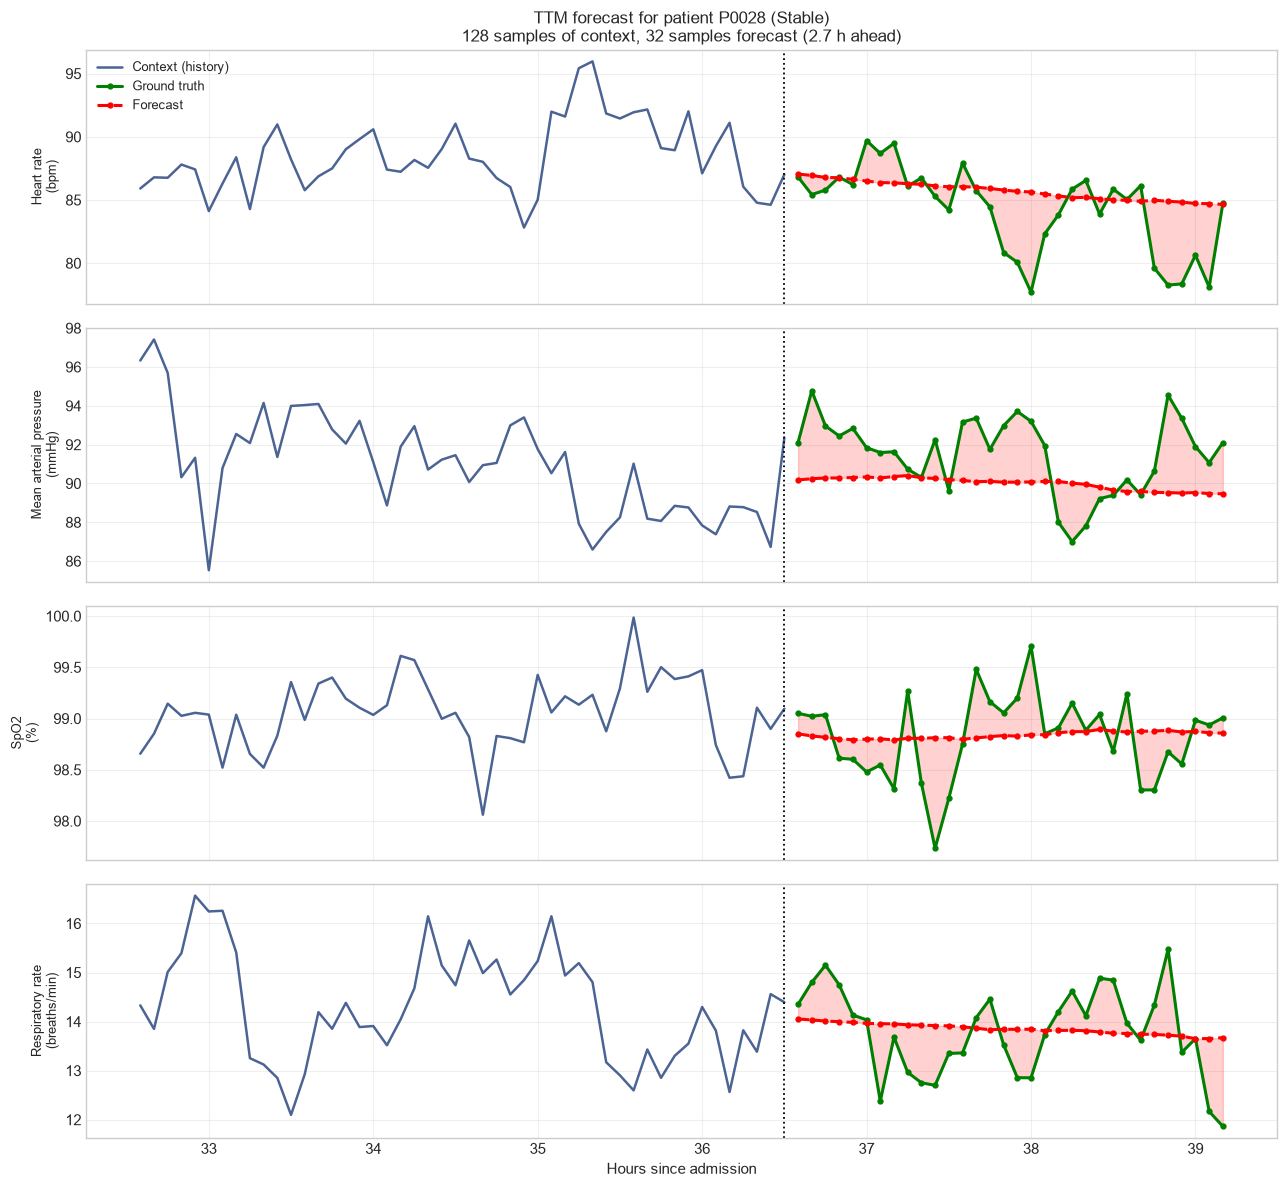

In [20]:
# ============================================================================
# VISUALIZE FORECAST VS ACTUAL - ONE PANEL PER CHANNEL
# ============================================================================

# Show the tail of the context so the forecast has something to join onto
CONTEXT_TAIL = 48   # 4 hours

fig, axes = plt.subplots(len(continuous_cols), 1, figsize=(13, 12), sharex=True)

context_df = vitals_data.iloc[sample_val_idx:sample_val_idx + CONTEXT_LENGTH]
context_hours = context_df['minutes_since_admission'].values / 60
horizon_hours = ground_truth_df['minutes_since_admission'].values / 60

for ax, i, col in zip(axes, range(len(continuous_cols)), continuous_cols):
    # Context (history)
    ax.plot(context_hours[-CONTEXT_TAIL:], context_df[col].values[-CONTEXT_TAIL:],
            color='#1f3d7a', linewidth=1.8, alpha=0.8, label='Context (history)')

    # Ground truth over the horizon
    ax.plot(horizon_hours, gt_original[:, i], color='green', linewidth=2.2,
            marker='o', markersize=3.5, label='Ground truth')

    # Forecast
    ax.plot(horizon_hours, pred_original[:, i], color='red', linestyle='--',
            linewidth=2.2, marker='o', markersize=3.5, label='Forecast')

    # Shade the gap between them
    ax.fill_between(horizon_hours, gt_original[:, i], pred_original[:, i],
                    alpha=0.18, color='red')

    # Mark where the forecast begins
    ax.axvline(context_hours[-1], color='black', linestyle=':', linewidth=1.3)

    ax.set_ylabel(f'{CHANNEL_LABELS[col]}\n({CHANNEL_UNITS[col]})', fontsize=9)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(loc='upper left', fontsize=9)
        ax.set_title(
            f"TTM forecast for patient {context_df['patient_id'].iloc[0]} "
            f"({ARCHETYPES[context_df['archetype'].iloc[0]]['label']})\n"
            f"{CONTEXT_LENGTH} samples of context, "
            f"{PREDICTION_HORIZON} samples forecast "
            f"({PREDICTION_HORIZON * SAMPLE_MINUTES / 60:.1f} h ahead)",
            fontsize=12
        )

axes[-1].set_xlabel('Hours since admission')

plt.tight_layout()
plt.show()


In [21]:
# ============================================================================
# MULTIPLE FORECAST WINDOWS EVALUATION
# ============================================================================

# Evaluate on multiple windows from the validation set
n_eval_windows = min(50, len(val_dataset))
all_errors = {col: {'mae': [], 'rmse': []} for col in continuous_cols}

print("Evaluating on multiple forecast windows...")
print("=" * 72)

for i in range(n_eval_windows):
    # Get window
    context_data, gt_data = val_dataset[i]
    context_np = context_data.numpy()
    gt_np = gt_data.numpy()

    # Forecast
    pred_norm, pred_orig = forecast_vitals(model, context_np, preprocessor, device)

    # Inverse transform ground truth
    gt_orig = preprocessor.inverse_transform_continuous(gt_np[:, :len(continuous_cols)])

    # Calculate errors
    for j, col in enumerate(continuous_cols):
        mae = np.mean(np.abs(pred_orig[:, j] - gt_orig[:, j]))
        rmse = np.sqrt(np.mean((pred_orig[:, j] - gt_orig[:, j])**2))
        all_errors[col]['mae'].append(mae)
        all_errors[col]['rmse'].append(rmse)

# Print average errors
print(f"\nAverage errors across {n_eval_windows} windows:")
print("-" * 72)
print(f"{'Channel':<26} {'MAE':>9} {'+/-':>8} {'RMSE':>9}  {'unit'}")
print("-" * 72)
for col in continuous_cols:
    avg_mae = np.mean(all_errors[col]['mae'])
    avg_rmse = np.mean(all_errors[col]['rmse'])
    std_mae = np.std(all_errors[col]['mae'])
    print(f"{CHANNEL_LABELS[col]:<26} {avg_mae:>9.3f} {std_mae:>8.3f} {avg_rmse:>9.3f}  {CHANNEL_UNITS[col]}")
print("=" * 72)


Evaluating on multiple forecast windows...



Average errors across 50 windows:
------------------------------------------------------------------------
Channel                          MAE      +/-      RMSE  unit
------------------------------------------------------------------------
Heart rate                     2.691    0.661     3.330  bpm
Mean arterial pressure         2.456    0.637     2.986  mmHg
SpO2                           0.492    0.108     0.597  %
Respiratory rate               0.992    0.216     1.211  breaths/min


---
## 7. Forecasting Across a Deterioration

A forecast that is accurate while nothing is happening is easy, and not very useful. The test
that matters clinically is what the model does when a patient starts to decline.

Below we put the two windows side by side:
- **Left**: a settled stretch on a stable patient. The right answer is "more of the same".
- **Right**: the window where the decline inside the forecast horizon is largest while the end
  of the context still looks quiet. The context looks ordinary; the next 2.5 hours do not.

### A note on how that second window was chosen

The obvious way to find it would be to look for the window where the `deteriorating` label
flips from 0 to 1. That turns out to be the wrong test. For a cardiac event the label marks the
*centre* of the crisis, not the start of the climb - so by the time it flips, the rise is
already several hours old and sits entirely inside the context. The model would have nothing
left to forecast, and the evaluation would flatter it.

So the cell below scores windows on what we actually care about: a large swing inside the
horizon, minus the spread across the last two hours of context. That picks out the window where
the patient genuinely looked settled and then genuinely was not.

### What to look for

Watch the heart rate and pressure panels on the right. A model that has learned only "carry the
recent level forward" will run a flat line straight through the event. A model that has learned
the *shape* of a deterioration from the other patients in the cohort will at least bend in the
right direction - usually late, and usually not far enough. That lag is the honest limit of
forecasting from the monitor trace alone, and it is worth seeing plainly rather than averaging
it away.

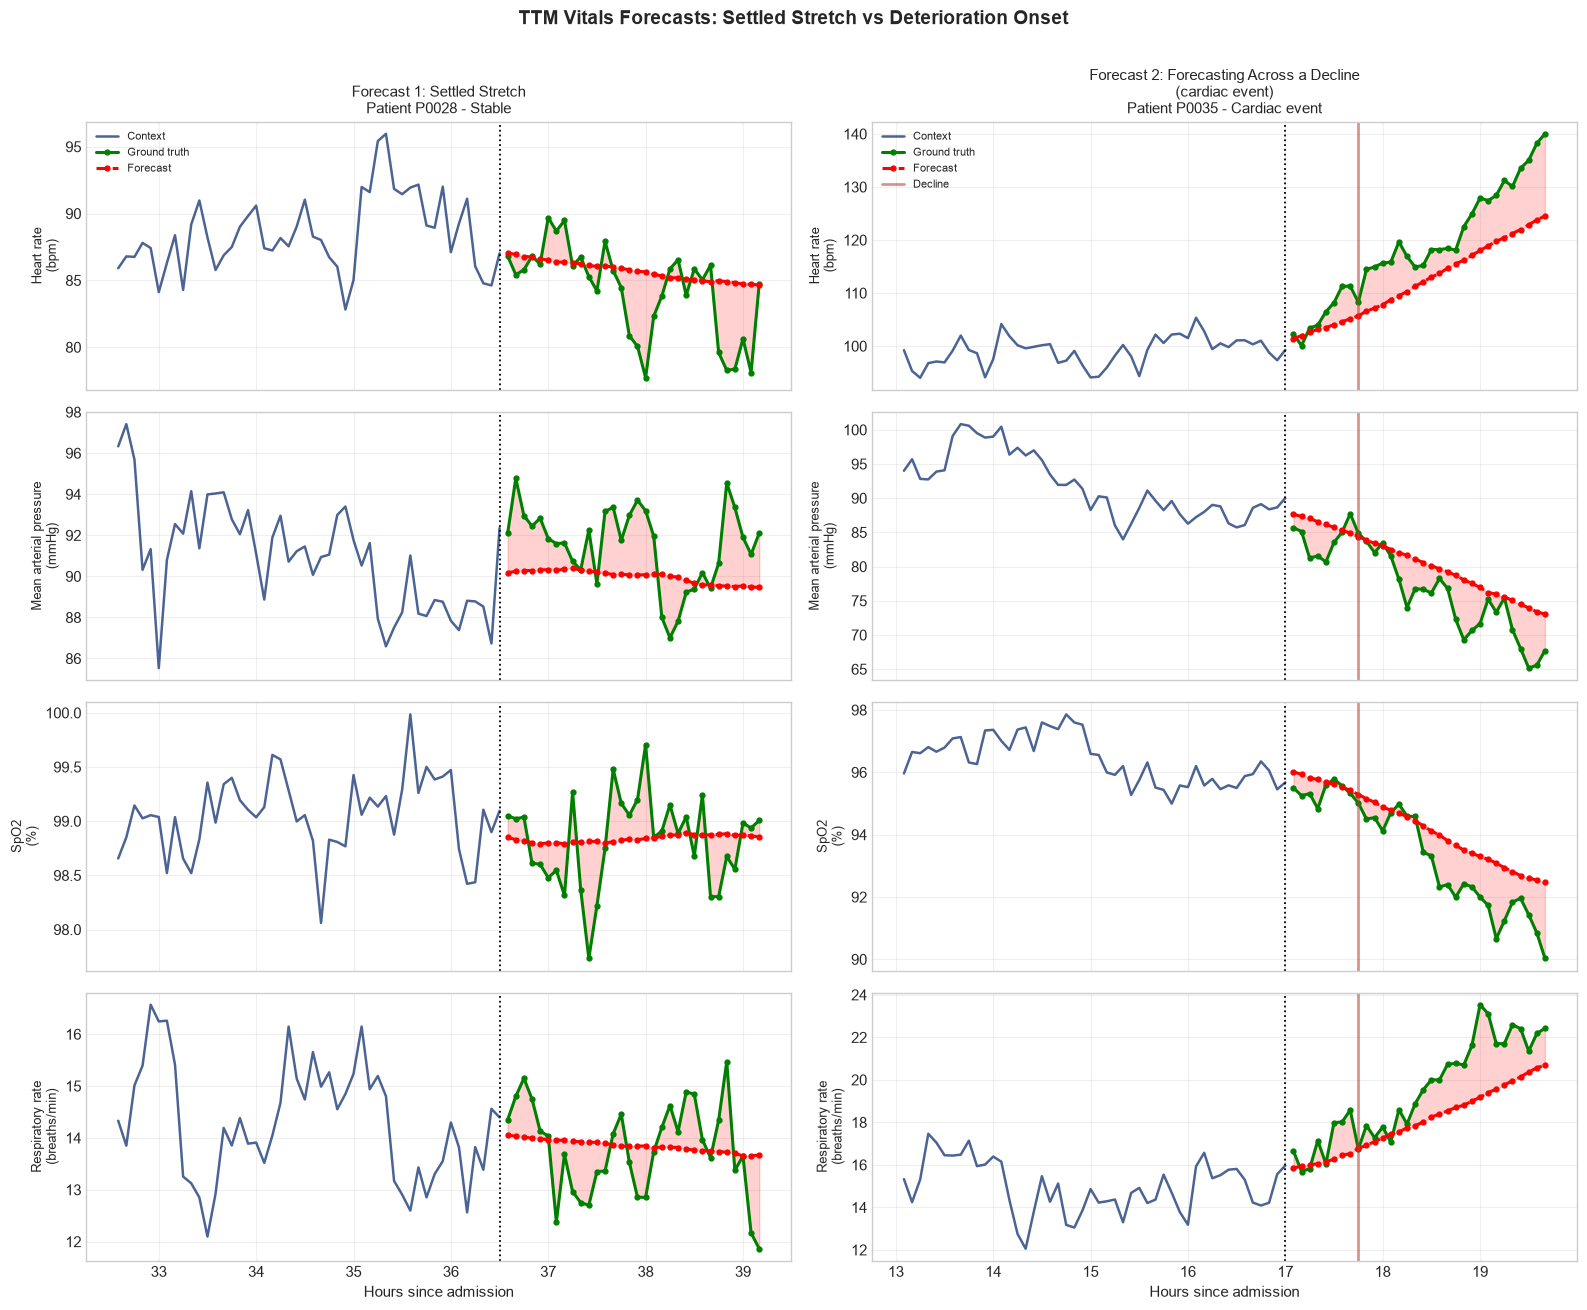


FORECAST ACCURACY: SETTLED STRETCH vs DECLINE

Settled stretch:
  Heart rate                 MAE    2.39 bpm
  Mean arterial pressure     MAE    2.05 mmHg
  SpO2                       MAE    0.32 %
  Respiratory rate           MAE    0.71 breaths/min

Across a decline:
  Heart rate                 MAE    6.62 bpm
  Mean arterial pressure     MAE    3.77 mmHg
  SpO2                       MAE    0.88 %
  Respiratory rate           MAE    1.47 breaths/min

------------------------------------------------------------------------------
Channel                       Settled    Decline    Times worse
------------------------------------------------------------------------------
Heart rate                       2.39       6.62           2.8x
Mean arterial pressure           2.05       3.77           1.8x
SpO2                             0.32       0.88           2.8x
Respiratory rate                 0.71       1.47           2.1x

Did the model see the decline coming?
  Last reading before th

In [22]:
# ============================================================================
# COMPREHENSIVE VISUALIZATION: SETTLED WINDOW vs DETERIORATION ONSET
# ============================================================================

CONTEXT_TAIL = 48   # show the last 4 hours of context

fig, axes = plt.subplots(len(continuous_cols), 2, figsize=(16, 13), sharex='col')

panels = [
    (0, "Forecast 1: Settled Stretch", context_df_1, ground_truth_df_1,
     gt_original_1, pred_original_1, None),
    (1, f"Forecast 2: Forecasting Across a Decline\n({onset_kind})", context_df_2,
     ground_truth_df_2, gt_original_2, pred_original_2, onset_step),
]

for column, title, ctx_df, gt_df, gt_vals, pred_vals, marker_step in panels:
    ctx_hours = ctx_df['minutes_since_admission'].values / 60
    hor_hours = gt_df['minutes_since_admission'].values / 60

    for row, col in enumerate(continuous_cols):
        ax = axes[row, column]

        ax.plot(ctx_hours[-CONTEXT_TAIL:], ctx_df[col].values[-CONTEXT_TAIL:],
                color='#1f3d7a', linewidth=1.8, alpha=0.8, label='Context')
        ax.plot(hor_hours, gt_vals[:, row], color='green', linewidth=2.2,
                marker='o', markersize=3.5, label='Ground truth')
        ax.plot(hor_hours, pred_vals[:, row], color='red', linestyle='--', linewidth=2.2,
                marker='o', markersize=3.5, label='Forecast')
        ax.fill_between(hor_hours, gt_vals[:, row], pred_vals[:, row], alpha=0.18, color='red')

        # Where the forecast begins
        ax.axvline(ctx_hours[-1], color='black', linestyle=':', linewidth=1.3)

        # Where the decline bites
        if marker_step is not None:
            ax.axvline(hor_hours[marker_step], color='#c0392b', linestyle='-', linewidth=2,
                       alpha=0.55, label='Decline')

        ax.set_ylabel(f'{CHANNEL_LABELS[col]}\n({CHANNEL_UNITS[col]})', fontsize=9)
        ax.grid(True, alpha=0.3)
        if row == 0:
            ax.set_title(f"{title}\nPatient {ctx_df['patient_id'].iloc[0]} - "
                         f"{ARCHETYPES[ctx_df['archetype'].iloc[0]]['label']}", fontsize=11)
            ax.legend(loc='upper left', fontsize=8)

    axes[-1, column].set_xlabel('Hours since admission')

plt.suptitle('TTM Vitals Forecasts: Settled Stretch vs Deterioration Onset',
             fontsize=14, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

# ============================================================================
# How much worse is the forecast when it has to cross the onset?
# ============================================================================
print("\n" + "=" * 78)
print("FORECAST ACCURACY: SETTLED STRETCH vs DECLINE")
print("=" * 78)

comparison = {}
for name, gt, pred in [("Settled stretch", gt_original_1, pred_original_1),
                       ("Across a decline", gt_original_2, pred_original_2)]:
    per_channel = {}
    for i, col in enumerate(continuous_cols):
        per_channel[col] = np.mean(np.abs(pred[:, i] - gt[:, i]))
    comparison[name] = per_channel

    print(f"\n{name}:")
    for col, mae in per_channel.items():
        print(f"  {CHANNEL_LABELS[col]:<26} MAE {mae:>7.2f} {CHANNEL_UNITS[col]}")

print("\n" + "-" * 78)
print(f"{'Channel':<26} {'Settled':>10} {'Decline':>10} {'Times worse':>14}")
print("-" * 78)
for col in continuous_cols:
    settled = comparison['Settled stretch'][col]
    decline = comparison['Across a decline'][col]
    ratio = decline / settled if settled > 0 else float('nan')
    print(f"{CHANNEL_LABELS[col]:<26} {settled:>10.2f} {decline:>10.2f} {ratio:>13.1f}x")
print("=" * 78)

# How much of the true swing did the model actually follow?
# Measure both from the last reading the model saw, which is the fair reference.
hr_true_swing = gt_original_2[:, 0].max() - ref_hr
hr_pred_swing = pred_original_2[:, 0].max() - ref_hr
map_true_swing = ref_map - gt_original_2[:, 1].min()
map_pred_swing = ref_map - pred_original_2[:, 1].min()

print("\nDid the model see the decline coming?")
print(f"  Last reading before the forecast: {ref_hr:.0f} bpm, {ref_map:.0f} mmHg")
if hr_true_swing > 0.5:
    print(f"  Heart rate rose {hr_true_swing:.0f} bpm; the forecast rose {hr_pred_swing:.0f} bpm "
          f"({hr_pred_swing / hr_true_swing:.0%} of the true swing)")
else:
    print("  Heart rate did not rise materially over this horizon")
if map_true_swing > 0.5:
    print(f"  Pressure fell {map_true_swing:.0f} mmHg; the forecast fell {map_pred_swing:.0f} mmHg "
          f"({map_pred_swing / map_true_swing:.0%} of the true swing)")
else:
    print("  Pressure did not fall materially over this horizon")
print("\nA forecast that captures only part of the swing still has value as a")
print("direction-of-travel signal, but it must never be read as an alarm threshold.")


---
## 8. Summary and Key Takeaways

### What We Built:
1. **Shared Vitals Generator**: realistic multi-channel monitor traces driven by clinical
   archetypes, used by this notebook and by notebook 02
2. **Data Preprocessing Pipeline**: normalization, encoding, and sequence creation that never
   lets a window straddle two patients
3. **Tiny Time Mixer Model**: a lightweight MLP-based architecture for time series forecasting
4. **Training Pipeline**: early stopping, learning-rate scheduling, and validation
5. **Forecasting System**: 2.5 hours ahead from 10.5 hours of context, evaluated both on
   settled stretches and across the onset of deterioration

### Key Concepts:
- **Patch Embedding**: dividing the series into patches shortens the sequence and captures
  local patterns
- **Temporal Mixing**: MLPs that learn patterns across time steps
- **Channel Mixing**: MLPs that learn relationships between channels - a rising heart rate and
  a falling pressure travel together, and the model can exploit that
- **Residual Connections**: help gradients flow during training

### What the Deterioration Evaluation Showed
Forecast error on a settled stretch tells you almost nothing about clinical usefulness. The
number that matters is the error across the turn, and it is always much larger. A model trained
on mostly-quiet data learns that the best guess is "more of the same", which is right almost
all of the time and wrong exactly when it counts. Any honest evaluation of a clinical
forecasting model has to report both numbers.

### Extensions:
- Weight the loss toward windows that contain an onset, and see what it costs elsewhere
- Add laboratory results and fluid balance as additional channels
- Produce probabilistic forecasts, so the widening uncertainty around an onset is visible
- Compare against a proper early-warning score (NEWS2) as a clinical baseline
- Deploy for real-time forecasting on a live monitoring stream

> **A clinical caution.** A forecast is not an alarm, and nothing in this notebook is validated
> for clinical use. The data is simulated and the model is a teaching example.

In [23]:
# ============================================================================
# FINAL MODEL SUMMARY
# ============================================================================

print("=" * 70)
print("TINY TIME MIXER (TTM) FOR ICU VITALS FORECASTING")
print("=" * 70)

print(f"\nDataset: simulated bedside monitoring (no real patient data)")
print(f"  - Clinical archetypes: {len(ARCHETYPES)} (stable, post-op, sepsis, cardiac)")
print(f"  - Total patients: {vitals_data['patient_id'].nunique()}")
print(f"  - Total readings: {len(vitals_data):,}")
print(f"  - Sampling interval: {SAMPLE_MINUTES} minutes")

print(f"\nModel Architecture:")
print(f"  - Patch Size: {PATCH_SIZE}")
print(f"  - Number of Patches: {CONTEXT_LENGTH // PATCH_SIZE}")
print(f"  - Embedding Dimension: {EMBED_DIM}")
print(f"  - Mixer Blocks: {N_MIXER_BLOCKS}")
print(f"  - Dropout: {DROPOUT}")
print(f"  - Total Parameters: {model.get_num_parameters():,}")

print(f"\nTraining Configuration:")
print(f"  - Training Sequences: {len(train_indices):,}")
print(f"  - Validation Sequences: {len(val_indices):,}")
print(f"  - Batch Size: {BATCH_SIZE}")
print(f"  - Epochs Trained: {len(history['train_loss'])}")
print(f"  - Best Val Loss: {early_stopping.best_loss:.6f}")

print(f"\nForecast Performance (settled window):")
print(f"  - Context: {CONTEXT_LENGTH} samples ({CONTEXT_LENGTH * SAMPLE_MINUTES / 60:.1f} hours)")
print(f"  - Horizon: {PREDICTION_HORIZON} samples ({PREDICTION_HORIZON * SAMPLE_MINUTES / 60:.1f} hours)")
for col in continuous_cols:
    print(f"  - {CHANNEL_LABELS[col]} MAE: {errors[col]['MAE']:.3f} {CHANNEL_UNITS[col]}")
print(f"  - Combined error: {normalised_mae:.3f} standard deviations")

print(f"\nForecast Performance (across a decline):")
for col in continuous_cols:
    mae = comparison['Across a decline'][col]
    print(f"  - {CHANNEL_LABELS[col]} MAE: {mae:.3f} {CHANNEL_UNITS[col]}")

print("\n" + "=" * 70)
print("Notebook execution complete")
print("=" * 70)


TINY TIME MIXER (TTM) FOR ICU VITALS FORECASTING

Dataset: simulated bedside monitoring (no real patient data)
  - Clinical archetypes: 4 (stable, post-op, sepsis, cardiac)
  - Total patients: 45
  - Total readings: 25,920
  - Sampling interval: 5 minutes

Model Architecture:
  - Patch Size: 16
  - Number of Patches: 8
  - Embedding Dimension: 32
  - Mixer Blocks: 2
  - Dropout: 0.3
  - Total Parameters: 119,024

Training Configuration:
  - Training Sequences: 15,012
  - Validation Sequences: 3,753
  - Batch Size: 32
  - Epochs Trained: 150
  - Best Val Loss: 0.049545

Forecast Performance (settled window):
  - Context: 128 samples (10.7 hours)
  - Horizon: 32 samples (2.7 hours)
  - Heart rate MAE: 2.394 bpm
  - Mean arterial pressure MAE: 2.054 mmHg
  - SpO2 MAE: 0.319 %
  - Respiratory rate MAE: 0.709 breaths/min
  - Combined error: 0.152 standard deviations

Forecast Performance (across a decline):
  - Heart rate MAE: 6.617 bpm
  - Mean arterial pressure MAE: 3.766 mmHg
  - SpO2 MA